## GCN regression

Explain what the input data, what it is. What the y^ is going to be etc. How to use that in further analysis.

Estimating costs linked to failure scenarios, preventive and corrective strategies.

In [118]:
import pandas as pd
import numpy as np
import plotly.express as px
import numpy as np
import plotly.graph_objects as go
import seaborn as sns
import matplotlib.pyplot as plt

### Import data here

Explain type of data being imported. Refer to script that creates these files.

Also, visualise the data.

__NB!__ remember to remove all non-necessary columns from dataframe before saving.

In [119]:
#df = pd.read_csv(r'data\tot_cost_failure_scenarios_041021_multicorr2.csv')
df = pd.read_csv(r'./data/tot_cost_failure_scenarios_180122_01.csv')
df_copy = df.copy()

In [121]:
df_ = df[['prev_id', 'Line10', 'Line11', 'Line18', 'Line19', 'Area1_prod', 'Area2_prod', 'Area3_prod', 'inter_area_flow', 'fault', 'corr', 
          'Total cost', 'Dispatch costs', 'Area1-corr', 'Area2-corr', 'Area3-corr', 'Area1-fault', 'Area2-fault', 'Area3-fault', 'Area1-fault2', 'Area2-fault2', 'Area3-fault2']]

## Visualise data

### Histogram

Get more extreme values when probabiity of failure is increased.

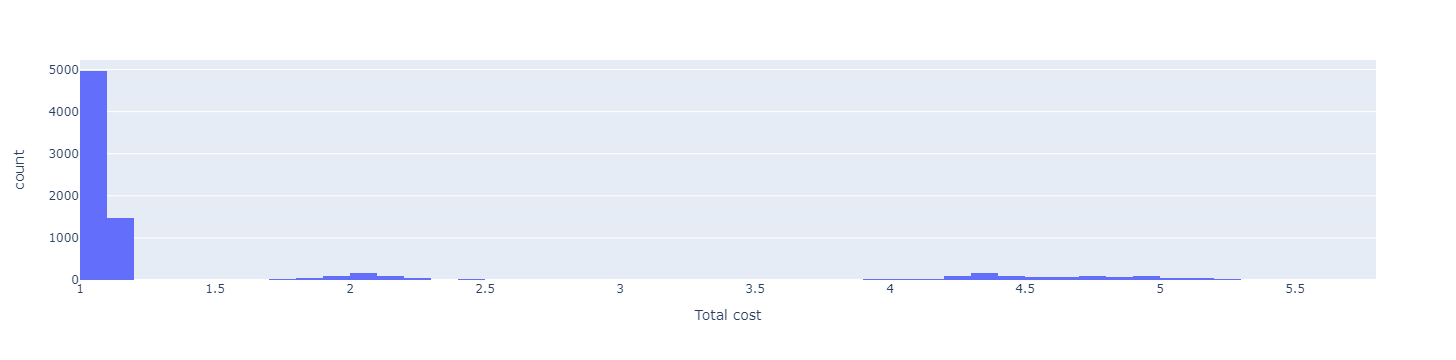

In [122]:
fig = px.histogram(df, x="Total cost")
fig.show()

### Correlation plot

Does not seem like any input strongly correlates with total cost. 

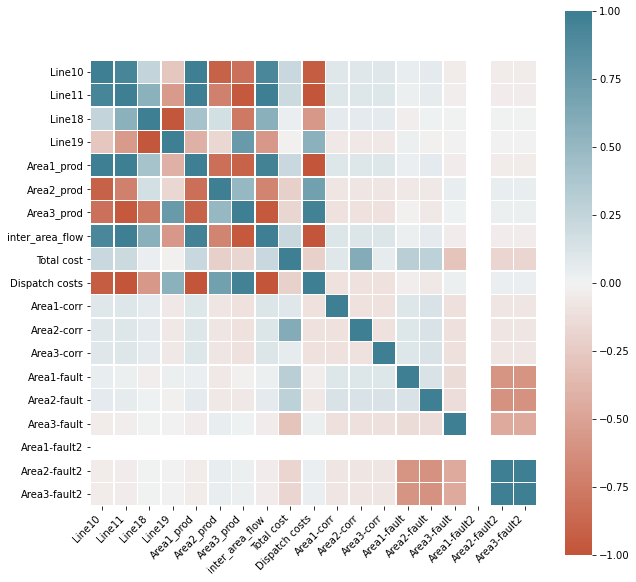

In [123]:
corr = df_.corr()
fig, ax = plt.subplots(figsize=(10,10))  
ax = sns.heatmap(
    corr, 
    vmin=-1, vmax=1, center=0,
    cmap=sns.diverging_palette(20, 220, n=200),
    square=True, linewidths=.5
)
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    horizontalalignment='right'
);

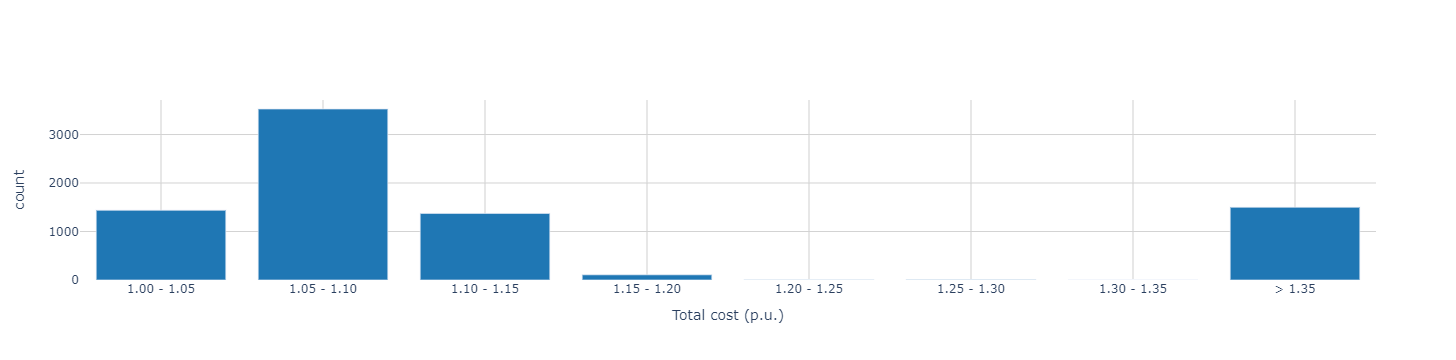

In [124]:
def plot_bar_with_outliers(series, name, end):
    start = int(series.min())
    size = 1

    # Making a histogram
    largest_value = series.max()
    if largest_value > end:
        hist = np.histogram(series, bins=np.concatenate([np.arange(start, end, 0.05), np.array([largest_value])], axis=None))
    else:
        hist = np.histogram(series, bins=np.concatenate([np.arange(start, end, 0.05), np.array([end])], axis=None))

    # Adding labels to the chart
    labels = []
    for i, j in zip(hist[1][0::1], hist[1][1::1]):
        if j <= end:
            labels.append('{:.2f} - {:.2f}'.format(i, j))
        else:
            labels.append('> {:.2f}'.format(i))

    # Plotting the graph
    data = [go.Bar(x=labels,
                   y=hist[0])]

    layout = go.Layout(
        xaxis = dict(
          title = name,
          gridcolor='lightgrey'),
        yaxis = dict(
          title = 'count',
          gridcolor='lightgrey'), 
        paper_bgcolor='rgba(0,0,0,0)',
        plot_bgcolor='rgba(0,0,0,0)'
    )
    fig = go.Figure(data=data, layout=layout)
    fig.update_traces(marker_color='#1F77B4')
    fig.show()

    #iplot(fig, filename='basic histogram')


plot_bar_with_outliers(df['Total cost'], 'Total cost (p.u.)', end=1.4)

## Run GCN-code

Given `df`, run code.

In [71]:
%run -i "gcn_regression.py"

Number of training graphs: 5156
Number of test graphs: 1294
Epoch: 001, Train Acc: 0.000655, Test Acc: 0.000743
Epoch: 002, Train Acc: 0.000348, Test Acc: 0.000420
Epoch: 003, Train Acc: 0.000294, Test Acc: 0.000352
Epoch: 004, Train Acc: 0.000280, Test Acc: 0.000336
Epoch: 005, Train Acc: 0.000265, Test Acc: 0.000318
Epoch: 006, Train Acc: 0.000259, Test Acc: 0.000308
Epoch: 007, Train Acc: 0.000252, Test Acc: 0.000301
Epoch: 008, Train Acc: 0.000243, Test Acc: 0.000291
Epoch: 009, Train Acc: 0.000243, Test Acc: 0.000290
Epoch: 010, Train Acc: 0.000235, Test Acc: 0.000280
Epoch: 011, Train Acc: 0.000232, Test Acc: 0.000275
Epoch: 012, Train Acc: 0.000232, Test Acc: 0.000277
Epoch: 013, Train Acc: 0.000227, Test Acc: 0.000272
Epoch: 014, Train Acc: 0.000225, Test Acc: 0.000269
Epoch: 015, Train Acc: 0.000223, Test Acc: 0.000267
Epoch: 016, Train Acc: 0.000221, Test Acc: 0.000263
Epoch: 017, Train Acc: 0.000221, Test Acc: 0.000262
Epoch: 018, Train Acc: 0.000218, Test Acc: 0.000261
Epoc

## Results

### Convergence plot

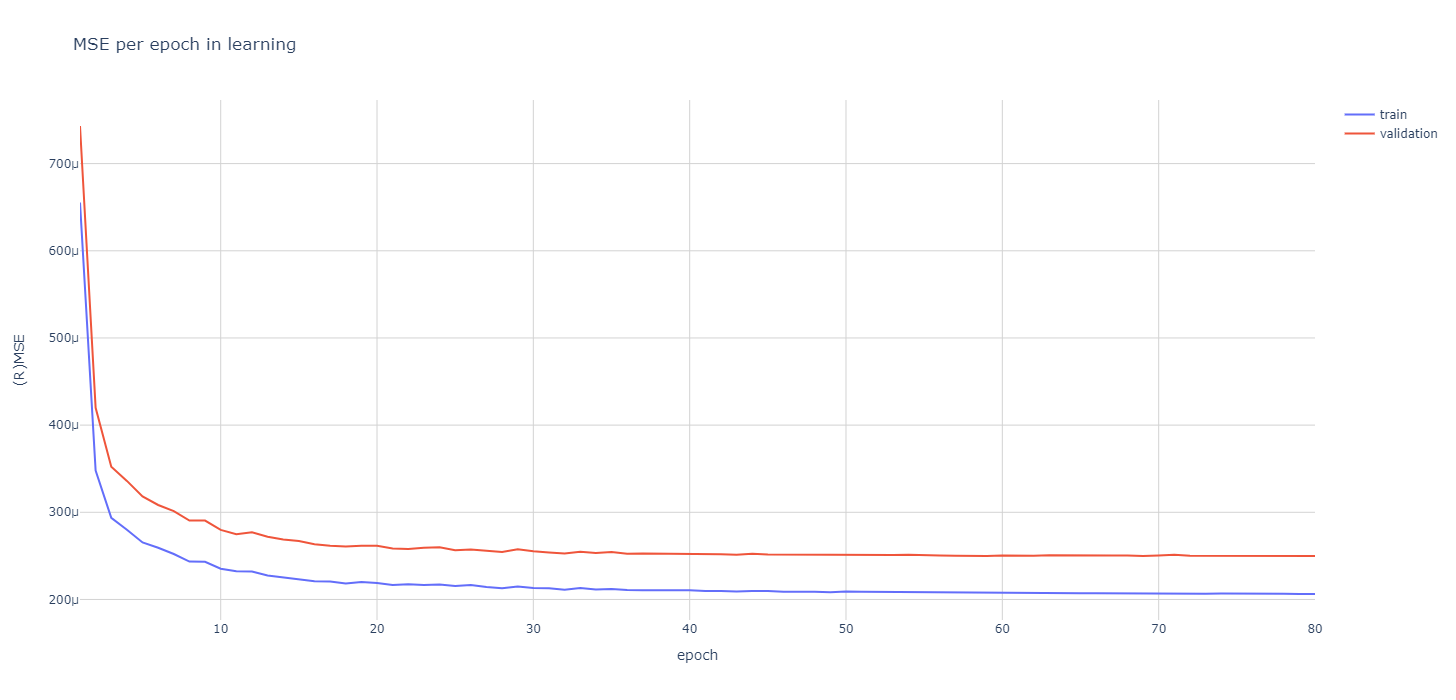

In [125]:
epoch_list = np.arange(1, len(train_list)+1)

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=epoch_list,
    y=train_list,
    name="train"       # this sets its legend entry
))


fig.add_trace(go.Scatter(
    x=epoch_list,
    y=test_list,
    name="validation"       # this sets its legend entry
))

fig.update_layout(
    title="MSE per epoch in learning",
    xaxis_title="epoch",
    yaxis_title="MSE",
     xaxis = dict(
        title = 'epoch',
        gridcolor='lightgrey'),
    yaxis = dict(
        title = '(R)MSE',
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)',
    width=1000,
    height=700
)

fig.show()

## Predicted scenarios sorted by cost

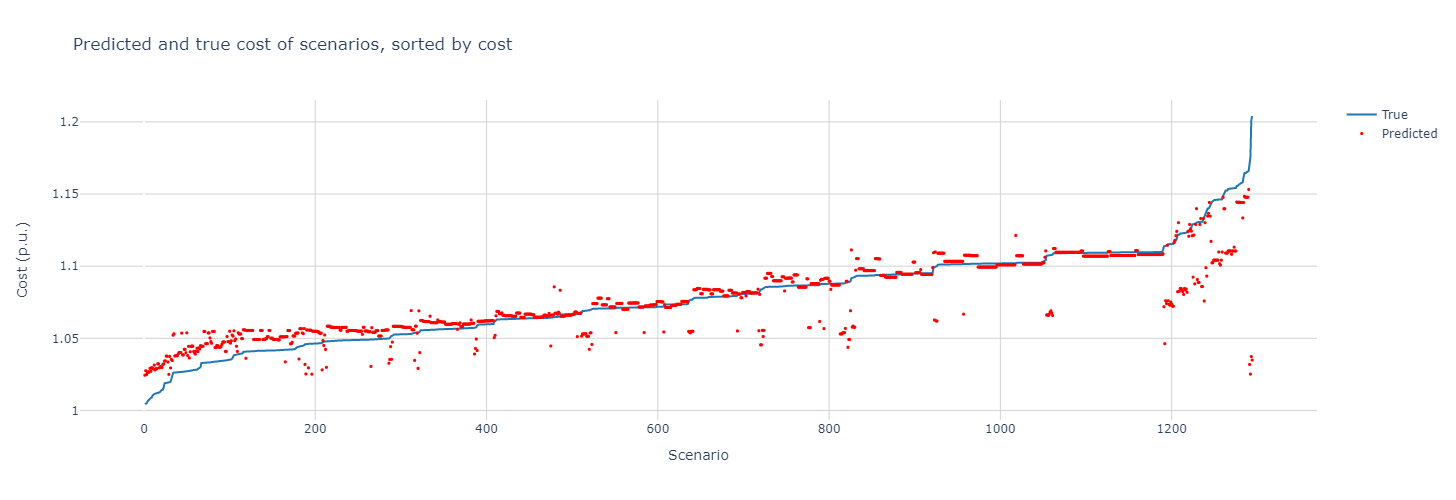

In [147]:
import plotly.graph_objects as go

layout = go.Layout(
    title = f'Predicted and true cost of scenarios, sorted by cost',
    xaxis = dict(
        gridcolor='lightgrey'),
    yaxis = dict(
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)

fig = go.Figure(layout=layout)

fig.add_trace(go.Scatter(x=x_values, y=plot_df['target'], mode='lines', line=dict(color='#1F77B4'), name="True"))
fig.add_trace(go.Scatter(x=x_values, y=plot_df['pred'], mode='markers', marker=dict(color='red', size=3), name="Predicted"))

fig.update_layout(
    xaxis_title='Scenario',
    yaxis_title='Cost (p.u.)',
    width=700, height=500
)
fig.show()

### Calculate cost per preventive strategy based on results from GCN-model

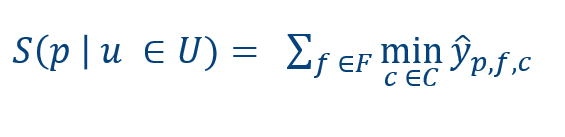

In [91]:
df_results["prev_id,fault"] = df_results[['prev_id', 'fault']].agg('-'.join, axis=1)

# Sort values in ascending order so value kept is corrective measure with lowest cost
df_prev = df_results.sort_values(['prev_id,fault', 'Total cost'])
df_d = df_prev.drop_duplicates('prev_id,fault',keep='first')
df_d.shape

(1110, 39)

In [93]:
df_d = df_d[['prev_id', 'inter_area_flow', 'fault', 'corr', 'Total cost', 'pred', 'acc', 'prev_id,fault']]
df_d

,prev_id,inter_area_flow,fault,corr,Total cost,pred,acc,"prev_id,fault"
24,p1000,264.559500,fault_L10,fault,1.070558,1.077843,0.007284,p1000-fault_L10
25,p1000,264.559500,fault_L11,fault,1.073625,1.075580,0.001955,p1000-fault_L11
26,p1000,264.559500,fault_L18,fault,1.071799,1.075488,0.003689,p1000-fault_L18
27,p1000,264.559500,fault_L19,fault,1.071576,1.073071,0.001494,p1000-fault_L19
60,p1009,231.462872,fault_L10,fault,1.093534,1.096933,0.003399,p1009-fault_L10
...,...,...,...,...,...,...,...,...
7901,p988,355.037643,fault_L19,fault,1.041714,1.048887,0.007173,p988-fault_L19
7913,p990,332.430419,fault_L10,fault,1.048197,1.057669,0.009471,p990-fault_L10
7914,p990,332.430419,fault_L11,fault,1.052965,1.057611,0.004646,p990-fault_L11
7915,p990,332.430419,fault_L18,fault,1.049443,1.055454,0.006011,p990-fault_L18


In [94]:
aggregations = {
    'inter_area_flow': 'mean', 
    'fault': list,
    'corr': list,
    'Total cost': 'sum',
    'pred': 'sum',
    'acc': 'sum'
}

new_df = df_d.groupby("prev_id").agg(aggregations)

mask = new_df["fault"].apply(lambda row: len(row)==4)
new_df = new_df[mask]

new_df["corr2"] = new_df["corr"].apply(lambda x: list(dict.fromkeys(x)))

#groups = new_df['corr2'].unique()

def classify_prev(corr_list):
    if len(corr_list)==1 and corr_list[0] == 'fault':
        return "N-1 safe"
    else:
        return "Not N-1 safe"

new_df["corr3"] = new_df["corr2"].apply(classify_prev)  

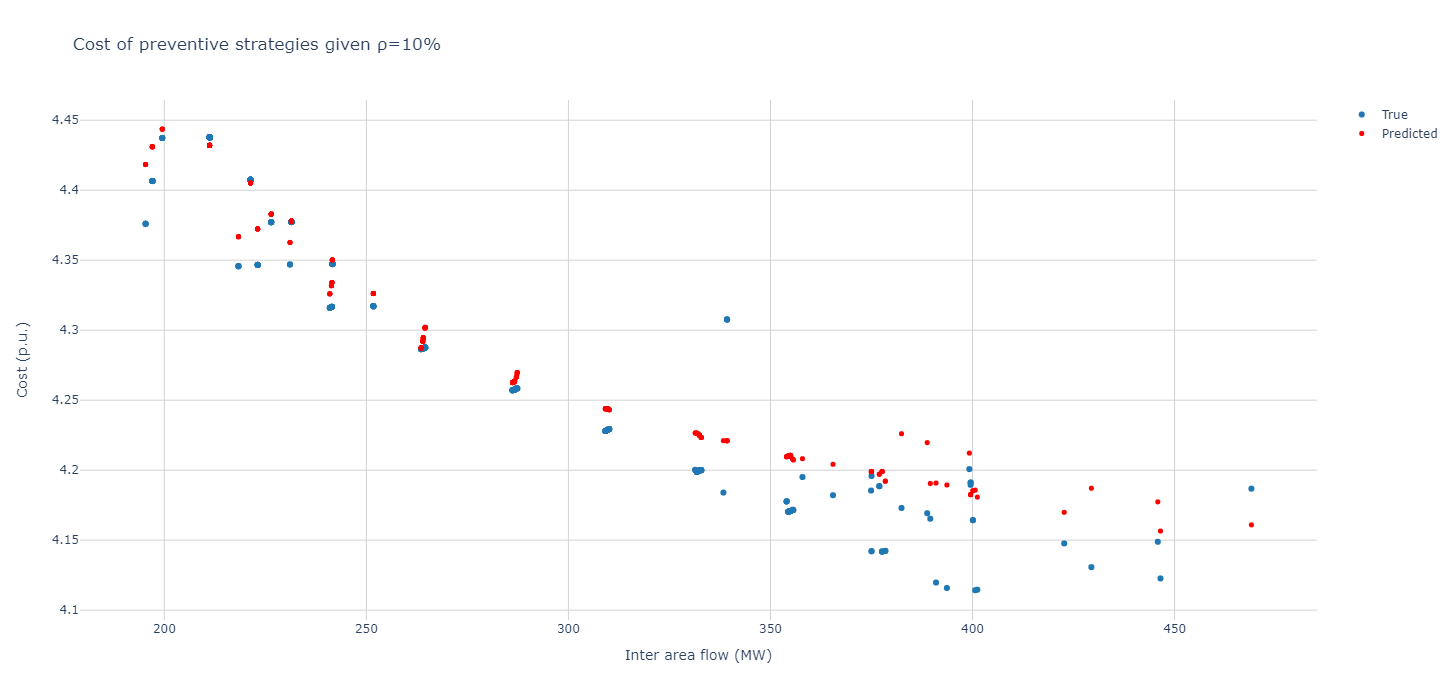

In [103]:
layout = go.Layout(
    title = f'Cost of preventive strategies given ρ=10%',
    xaxis = dict(
        gridcolor='lightgrey'),
    yaxis = dict(
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)

fig = go.Figure(layout=layout)

fig.add_trace(go.Scatter(x=new_df["inter_area_flow"], y=new_df['Total cost'], mode='markers', line=dict(color='#1F77B4'), name="True", 
                            hovertext = new_df.index))
fig.add_trace(go.Scatter(x=new_df["inter_area_flow"], y=new_df['pred'], mode='markers', marker=dict(color='red', size=5), name="Predicted"))

fig.update_layout(
    xaxis_title='Inter area flow (MW)',
    yaxis_title='Cost (p.u.)',
    width=1000, height=700
)
fig.show()

In [116]:
df_ = df_results[['prev_id', 'fault', 'corr', 'Dispatch costs', 'CENS', 'FCR cost', 'Redispatch cost', 'SPS cost', 'Total cost', 'pred']]
df_[df_["prev_id"]=="p781"]

,prev_id,fault,corr,Dispatch costs,CENS,FCR cost,Redispatch cost,SPS cost,Total cost,pred
6736,p781,fault_L10,fault,1.042014,0.0,0.004933,2.237200e-02,0.000000,1.044745,1.056660
6739,p781,fault_L11,corr_L09,1.042014,0.0,0.143896,7.094201e-06,0.303887,1.086793,1.057392
6743,p781,fault_L18,corr_L09,1.042014,0.0,0.156280,7.079663e-09,0.303887,1.088031,1.053049
6747,p781,fault_L19,corr_L09,1.042014,0.0,0.156789,7.079661e-09,0.303887,1.088082,1.053894


In [178]:
df_ = df_copy[['prev_id', 'fault', 'corr', 'Dispatch costs', 'CENS', 'FCR cost', 'Redispatch cost', 'SPS cost', 'Total cost']]
df_[df_["prev_id"]=="p781"]

,prev_id,fault,corr,Dispatch costs,CENS,FCR cost,Redispatch cost,SPS cost,Total cost
6736,p781,fault_L10,fault,1.042014,0.000000,0.004933,2.237200e-02,0.000000,1.044745
6737,p781,fault_L11,corr_G12,1.042014,7.667480,0.160413,1.057507e-01,0.303887,1.865767
6738,p781,fault_L11,corr_G18,1.042014,12.984070,0.309402,1.405167e-01,0.303887,2.415802
6739,p781,fault_L11,corr_L09,1.042014,0.000000,0.143896,7.094201e-06,0.303887,1.086793
6740,p781,fault_L11,fault,1.042014,7.178218,0.023093,2.301421e-02,0.000000,1.764447
6741,p781,fault_L18,corr_G12,1.042014,9.316356,0.004035,4.020961e-03,0.303887,2.004844
6742,p781,fault_L18,corr_G18,1.042014,10.462862,0.302402,1.337981e-01,0.303887,2.162309
6743,p781,fault_L18,corr_L09,1.042014,0.000000,0.156280,7.079663e-09,0.303887,1.088031
6744,p781,fault_L18,fault,1.042014,9.311652,0.003881,3.694799e-03,0.000000,1.973937
6745,p781,fault_L19,corr_G12,1.042014,9.371984,0.003165,3.152759e-03,0.303887,2.010233


In [83]:
new_df["corr2"] = new_df["corr"].apply(lambda x: tuple(dict.fromkeys(x)))
groups = new_df['corr2'].unique()
groups

array([('fault',), ('corr_L09', 'fault'), ('corr_G12', 'fault'),
       ('fault', 'corr_L09'), ('corr_G12', 'fault', 'corr_L09')],
      dtype=object)

In [151]:
#failure_rate = 100
#df_ = pd.read_csv(r'data\tot_cost_failure_scenarios_041021_multicorr2.csv')

failure_rate = 10
df_ = pd.read_csv(r'./data/tot_cost_failure_scenarios_180122_01.csv')

#failure_rate = 1
#df_ = pd.read_csv(r'./data/tot_cost_failure_scenarios_180122_001.csv')

df_["prev_id,fault"] = df_[['prev_id', 'fault']].agg('-'.join, axis=1)

# Sort values in ascending order so value kept is corrective measure with lowest cost
df_prev = df_.sort_values(['prev_id,fault', 'Total cost'])
df_d = df_prev.drop_duplicates('prev_id,fault',keep='first')
df_d.shape

aggregations = {
    'inter_area_flow': 'mean', 
    'fault': list,
    'corr': list,
    'Total cost': 'sum'
}


new_df = df_d.groupby("prev_id").agg(aggregations)

mask = new_df["fault"].apply(lambda row: len(row)==4)
new_df = new_df[mask]

new_df["corr2"] = new_df["corr"].apply(lambda x: list(dict.fromkeys(x)))

#groups = new_df['corr2'].unique()

def classify_prev(corr_list):
    if len(corr_list)==1 and corr_list[0] == 'fault':
        return "N-1 safe"
    else:
        return "Not N-1 safe"

new_df["corr3"] = new_df["corr2"].apply(classify_prev)  

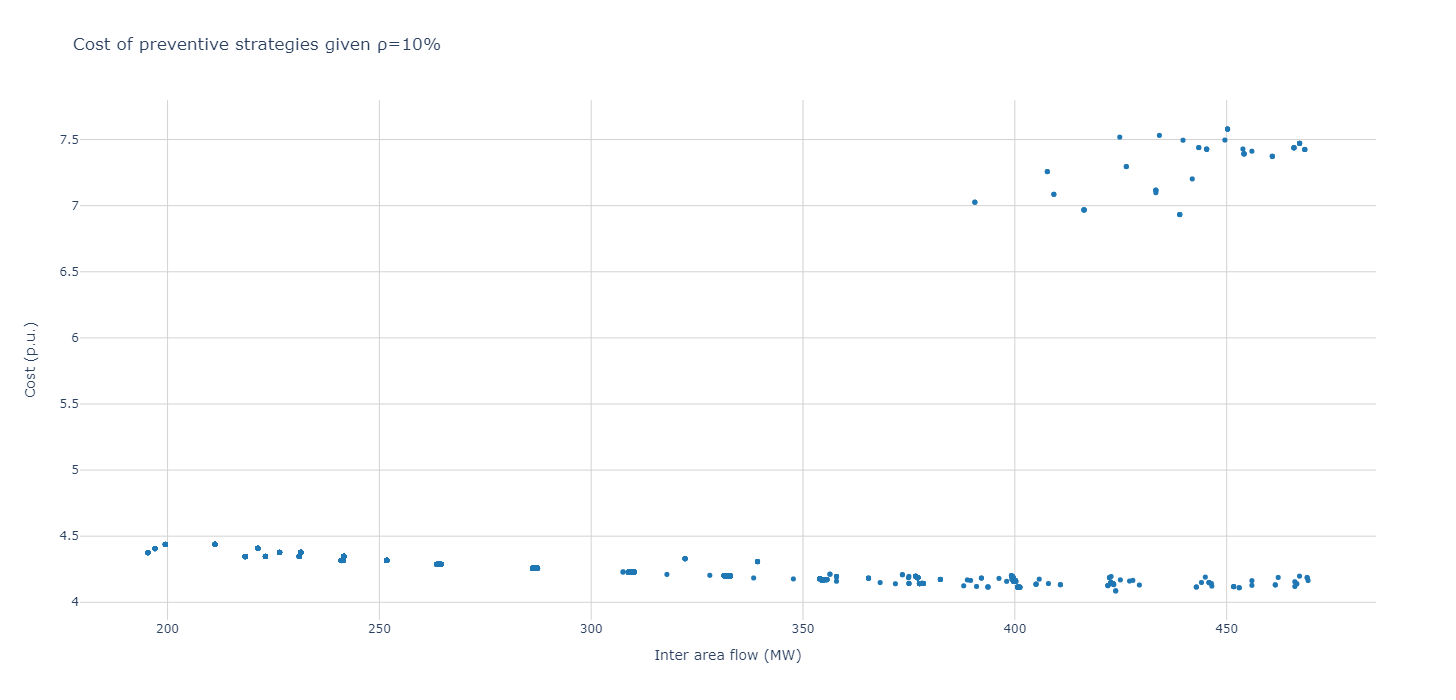

In [158]:
layout = go.Layout(
    title = 'Cost of preventive strategies given ρ={}%'.format(failure_rate),
    xaxis = dict(
        gridcolor='lightgrey'),
    yaxis = dict(
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)

fig = go.Figure(layout=layout)

groups = new_df['corr3'].unique()

colors = ["green", "red"]

#for index, group in enumerate(groups):
#    new_df2 = new_df[new_df['corr3'] == group]
#    fig.add_trace(go.Scatter(x=new_df2["inter_area_flow"], y=new_df2['Total cost'], line=dict(color=colors[index]), mode='markers', name=str(group)))#line=dict(color='#1F77B4'), name="True"))


fig.add_trace(go.Scatter(x=new_df["inter_area_flow"], y=new_df['Total cost'], mode='markers', hovertext = new_df.index, marker=dict(color='#1F77B4', size=5), name="Predicted"))

fig.update_layout(
    xaxis_title='Inter area flow (MW)',
    yaxis_title='Cost (p.u.)',
    width=1000, height=700
)
fig.show()

In [176]:
new_df_ = new_df[new_df["inter_area_flow"]>390]
pred_low_cost_id = new_df_[new_df_["Total cost"]<5].index

In [172]:
pred_high_cost_id = new_df[new_df["Total cost"]>5].index
df_cap = pd.read_csv(r'./data/prev_line_caps.csv').set_index("Unnamed: 0")
df_cap

,Line10,Line11,Line18,Line19
Unnamed: 0,,,,
p1,100.0,100.0,100.0,100.0
p10,100.0,55.0,100.0,100.0
p100,100.0,65.0,35.0,100.0
p101,100.0,60.0,35.0,100.0
p102,100.0,55.0,35.0,100.0
...,...,...,...,...
p95,100.0,35.0,40.0,100.0
p96,100.0,30.0,40.0,100.0
p97,100.0,80.0,35.0,100.0


In [173]:
df_cap[df_cap.index.isin(pred_high_cost_id)]

,Line10,Line11,Line18,Line19
Unnamed: 0,,,,
p161,100.0,75.0,50.0,30.0
p162,100.0,70.0,50.0,30.0
p175,100.0,65.0,45.0,35.0
p188,100.0,55.0,45.0,30.0
p309,100.0,100.0,35.0,45.0
p354,100.0,40.0,40.0,45.0
p360,100.0,65.0,35.0,45.0
p363,100.0,50.0,35.0,45.0
p369,100.0,65.0,30.0,45.0


In [188]:
df_copy[df_copy["prev_id"]=="p162"][['prev_id', 'Line10', 'Line11', 'Line18', 'Line19', 'Area1_prod',
       'Area2_prod', 'Area3_prod', 'Area1_load', 'Area2_load', 'Area3_load',
       'inter_area_flow', 'fault', 'corr', 'Dispatch costs', 'CENS',
       'FCR cost', 'Redispatch cost', 'SPS cost', 'Total cost']]

,prev_id,Line10,Line11,Line18,Line19,Area1_prod,Area2_prod,Area3_prod,Area1_load,Area2_load,Area3_load,inter_area_flow,fault,corr,Dispatch costs,CENS,FCR cost,Redispatch cost,SPS cost,Total cost
2164,p162,121.589963,186.999793,60.794982,-55.388241,541.523243,97.090365,465.013671,129.41124,102.497107,768.196686,424.772978,fault_L10,corr_G12,1.014049,34.541545,0.187017,0.421032,0.303887,4.559397
2165,p162,121.589963,186.999793,60.794982,-55.388241,541.523243,97.090365,465.013671,129.41124,102.497107,768.196686,424.772978,fault_L10,corr_G18,1.014049,43.897992,0.211057,0.540926,0.303887,5.509435
2166,p162,121.589963,186.999793,60.794982,-55.388241,541.523243,97.090365,465.013671,129.41124,102.497107,768.196686,424.772978,fault_L10,corr_L09,1.014049,32.387186,0.144206,0.390369,0.303887,4.336614
2167,p162,121.589963,186.999793,60.794982,-55.388241,541.523243,97.090365,465.013671,129.41124,102.497107,768.196686,424.772978,fault_L10,fault,1.014049,38.836329,0.043030,0.444144,0.000000,4.946399
2168,p162,121.589963,186.999793,60.794982,-55.388241,541.523243,97.090365,465.013671,129.41124,102.497107,768.196686,424.772978,fault_L11,fault,1.014049,0.000000,0.827322,0.500089,0.000000,1.146790
2169,p162,121.589963,186.999793,60.794982,-55.388241,541.523243,97.090365,465.013671,129.41124,102.497107,768.196686,424.772978,fault_L18,fault,1.014049,0.000000,0.004210,0.029607,0.000000,1.017430
2170,p162,121.589963,186.999793,60.794982,-55.388241,541.523243,97.090365,465.013671,129.41124,102.497107,768.196686,424.772978,fault_L19,fault,1.014049,0.000000,0.003267,0.028958,0.000000,1.017271


In [189]:
df_copy[df_copy["prev_id"]=="p161"][['prev_id', 'Line10', 'Line11', 'Line18', 'Line19', 'Area1_prod',
       'Area2_prod', 'Area3_prod', 'Area1_load', 'Area2_load', 'Area3_load',
       'inter_area_flow', 'fault', 'corr', 'Dispatch costs', 'CENS',
       'FCR cost', 'Redispatch cost', 'SPS cost', 'Total cost']]

,prev_id,Line10,Line11,Line18,Line19,Area1_prod,Area2_prod,Area3_prod,Area1_load,Area2_load,Area3_load,inter_area_flow,fault,corr,Dispatch costs,CENS,FCR cost,Redispatch cost,SPS cost,Total cost
2157,p161,127.13325,190.733258,60.794982,-55.467909,550.799995,91.626748,461.200536,129.41124,102.497107,768.196686,434.129399,fault_L10,corr_G12,1.010989,34.599372,0.199116,0.424839,0.303887,4.563710
2158,p161,127.13325,190.733258,60.794982,-55.467909,550.799995,91.626748,461.200536,129.41124,102.497107,768.196686,434.129399,fault_L10,corr_G18,1.010989,42.562474,0.217729,0.538631,0.303887,5.373261
2159,p161,127.13325,190.733258,60.794982,-55.467909,550.799995,91.626748,461.200536,129.41124,102.497107,768.196686,434.129399,fault_L10,corr_L09,1.010989,32.930370,0.144201,0.398665,0.303887,4.388701
2160,p161,127.13325,190.733258,60.794982,-55.467909,550.799995,91.626748,461.200536,129.41124,102.497107,768.196686,434.129399,fault_L10,fault,1.010989,39.451639,0.041439,0.454068,0.000000,5.005703
2161,p161,127.13325,190.733258,60.794982,-55.467909,550.799995,91.626748,461.200536,129.41124,102.497107,768.196686,434.129399,fault_L11,fault,1.010989,0.000000,0.649630,0.378072,0.000000,1.113759
2162,p161,127.13325,190.733258,60.794982,-55.467909,550.799995,91.626748,461.200536,129.41124,102.497107,768.196686,434.129399,fault_L18,fault,1.010989,0.000000,0.004166,0.029922,0.000000,1.014398
2163,p161,127.13325,190.733258,60.794982,-55.467909,550.799995,91.626748,461.200536,129.41124,102.497107,768.196686,434.129399,fault_L19,fault,1.010989,0.000000,0.003231,0.029280,0.000000,1.014240


In [177]:
df_cap[df_cap.index.isin(pred_low_cost_id)]

,Line10,Line11,Line18,Line19
Unnamed: 0,,,,
p1,100.0,100.0,100.0,100.0
p107,100.0,30.0,35.0,100.0
p16,100.0,95.0,45.0,100.0
p163,100.0,65.0,50.0,30.0
p176,100.0,60.0,45.0,35.0
p238,100.0,65.0,100.0,45.0
p239,100.0,60.0,100.0,45.0
p251,100.0,65.0,100.0,40.0
p260,100.0,80.0,100.0,35.0


In [160]:
df_ = df_copy[['prev_id', 'fault', 'corr', 'Dispatch costs', 'CENS', 'FCR cost', 'Redispatch cost', 'SPS cost', 'Total cost']]
df_[df_["prev_id"]=="p494"]

,prev_id,fault,corr,Dispatch costs,CENS,FCR cost,Redispatch cost,SPS cost,Total cost
4881,p494,fault_L10,corr_G12,1.015522,31.665016,0.138804,4.294796e-01,0.303887,4.269241
4882,p494,fault_L10,corr_G18,1.015522,41.271439,0.314391,5.783335e-01,0.303887,5.262327
4883,p494,fault_L10,corr_L09,1.015522,27.443481,0.151426,3.479427e-01,0.303887,3.840196
4884,p494,fault_L10,fault,1.015522,36.788491,0.008907,4.427320e-01,0.000000,4.739535
4885,p494,fault_L11,fault,1.015522,0.000000,0.415801,3.197210e-01,0.000000,1.089074
4886,p494,fault_L18,fault,1.015522,0.000000,0.005650,3.120657e-02,0.000000,1.019208
4887,p494,fault_L19,corr_G12,1.015522,9.327559,0.022718,1.303601e-02,0.303887,1.982242
4888,p494,fault_L19,corr_G18,1.015522,10.327997,0.302136,1.377514e-01,0.303887,2.122699
4889,p494,fault_L19,corr_L09,1.015522,0.000000,0.156973,7.079649e-09,0.303887,1.061608
4890,p494,fault_L19,fault,1.015522,0.000000,0.004194,3.003466e-02,0.000000,1.018945


## Stacked bar plot

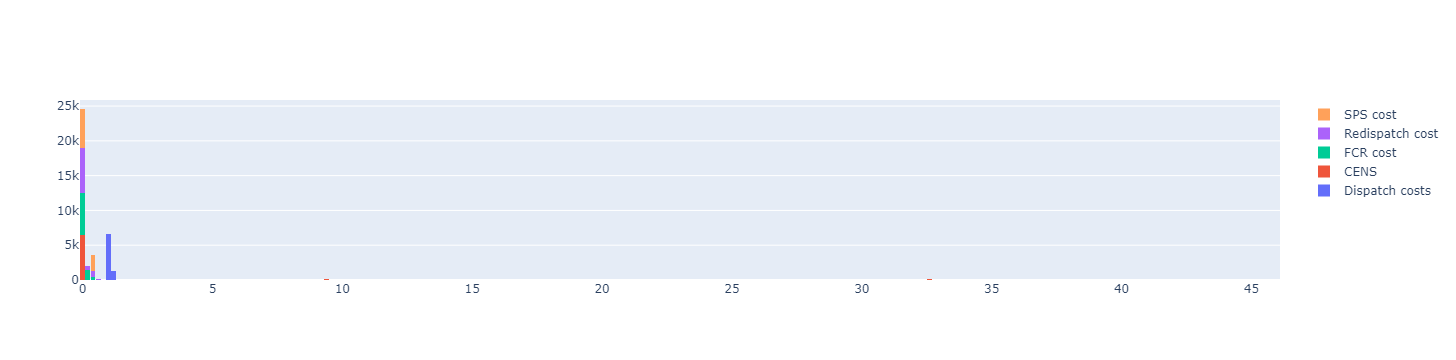

In [43]:
cost_types = ["Dispatch costs", "CENS", "FCR cost", "Redispatch cost", "SPS cost"]

fig = go.Figure(go.Histogram(
    x=df[cost_types[0]],
    bingroup=1, name=cost_types[0]))

fig.add_trace(go.Histogram(
    x=df[cost_types[1]],
    bingroup=1, name=cost_types[1]))

fig.add_trace(go.Histogram(
    x=df[cost_types[2]],
    bingroup=1, name=cost_types[2]))

fig.add_trace(go.Histogram(
    x=df[cost_types[3]],
    bingroup=1, name=cost_types[3]))

fig.add_trace(go.Histogram(
    x=df[cost_types[4]],
    bingroup=1, name=cost_types[4]))

fig.update_layout(
    barmode="stack",
    bargap=0.1)

fig.show()

## Box plots

In [ ]:
df_L10 = df[df["fault"]=="fault_L10"]
df_L11 = df[df["fault"]=="fault_L11"]
df_L18 = df[df["fault"]=="fault_L18"]
df_L19 = df[df["fault"]=="fault_L19"]

df_fault = df[df["corr"]=="fault"]
df_G12 = df[df["corr"]=="corr_G12"]
df_G18 = df[df["corr"]=="corr_G18"]
df_L09 = df[df["corr"]=="corr_L09"]

fault_types = ["fault_L10", "fault_L11", "fault_L18", "fault_L19"]

fig = go.Figure()
for fault in fault_types:
    fig.add_trace(go.Box(y=df["Total cost"][df["fault"]==fault], name=fault))
    
fig.update_layout(
    title={
        'text': "True total cost per fault"})

fig.show()

## Predicted scenarios sorted by cost

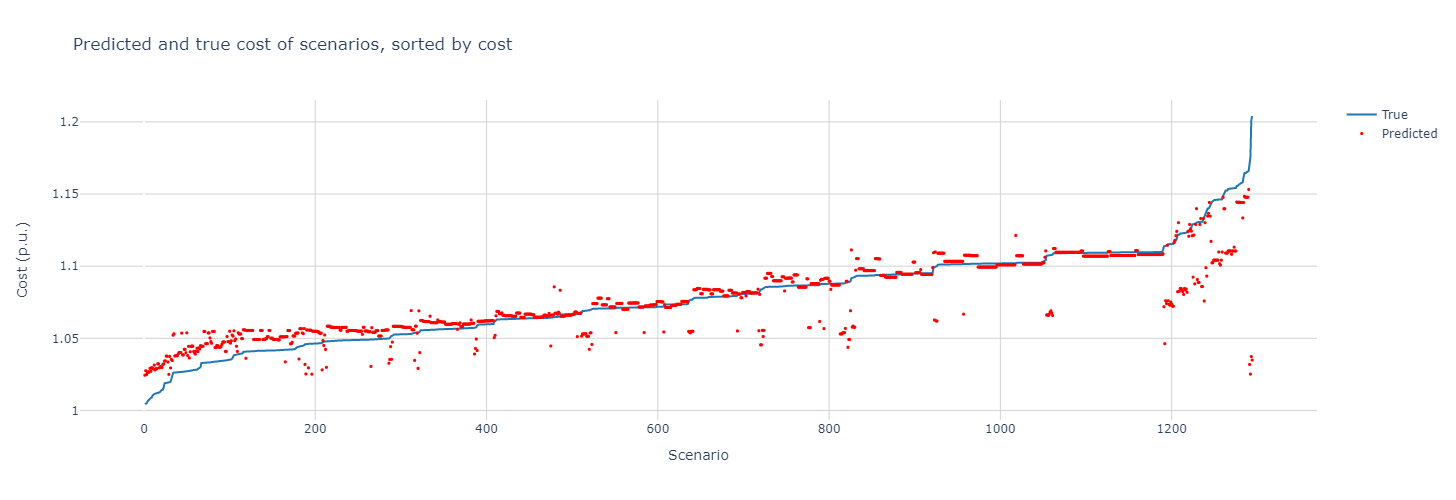

In [145]:
import plotly.graph_objects as go

layout = go.Layout(
    title = f'Predicted and true cost of scenarios, sorted by cost',
    xaxis = dict(
        gridcolor='lightgrey'),
    yaxis = dict(
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)

fig = go.Figure(layout=layout)

fig.add_trace(go.Scatter(x=x_values, y=plot_df['target'], mode='lines', line=dict(color='#1F77B4'), name="True"))
fig.add_trace(go.Scatter(x=x_values, y=plot_df['pred'], mode='markers', marker=dict(color='red', size=3), name="Predicted"))

fig.update_layout(
    xaxis_title='Scenario',
    yaxis_title='Cost (p.u.)',
    width=700, height=500
)
fig.show()

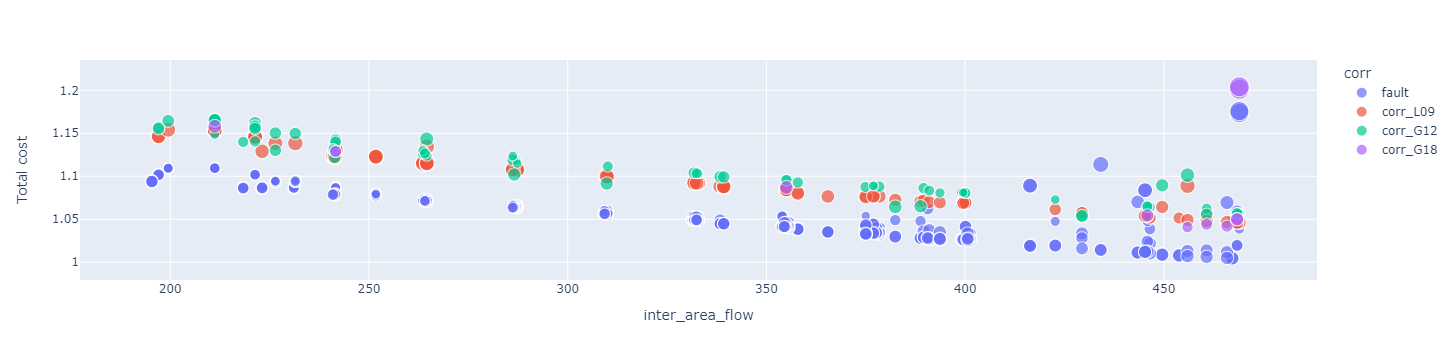

In [146]:
df_results["acc"] = df_results.apply(lambda row: abs(row["Total cost"]-row["pred"]), axis=1)
df_results["log"] = df_results["acc"].apply(lambda x: 1/abs(np.log(x)))
fig = px.scatter(df_results, x="inter_area_flow", y="Total cost", color="corr", hover_data=['corr'], size="log")
fig.show()